# 01 · EDA des données StatsBomb pour l'expected threat (xT)

Objectif : comprendre ce que les données ouvertes de StatsBomb permettent pour un modèle xT
(et sa version bayésienne), et préparer une table d'actions propre.

Ce dont xT a besoin, pour chaque case $z$ d'une grille du terrain (Singh, 2019) :

$$xT(z) = s_z \, g_z + m_z \sum_{z'} T_{z \to z'} \, xT(z')$$

* $s_z, m_z$ : probabilité de tirer / de bouger le ballon depuis $z$,
* $g_z$ : probabilité de marquer sur un tir depuis $z$ (≈ xG),
* $T_{z \to z'}$ : probabilité qu'un mouvement (passe, conduite, dribble) réussi aille de $z$ à $z'$.

Le notebook regarde donc : la couverture des compétitions, la position des événements,
le taux de réussite des passes / conduites / dribbles, les tirs et buts, et surtout la
**rareté des données par case** (ce qui motive des priors bayésiens).

Données : par défaut Coupe du monde 2022 (64 matchs) + Premier League 2015/16 (380 matchs).
Le premier lancement télécharge environ 1 Go de JSON (≈ 2 min), ensuite tout vient du cache
`data/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bxt.data import load_competitions, load_matches, load_actions, PITCH_X, PITCH_Y
from bxt.features import add_cells, count_grid
from bxt.visualizations import grid_heatmap

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
NX, NY = 16, 12  # grille de Singh (2019) : 192 cases de 7.5 x 6.67 unités StatsBomb

## 1. Couverture des données ouvertes

StatsBomb publie une sélection de compétitions, souvent incomplètes (ex. seulement les matchs
de Messi pour la Liga). Pour un xT il faut beaucoup d'actions : les saisons complètes de
championnat sont les plus utiles.

In [2]:
comps = load_competitions()
rows = []
for r in comps.itertuples():
    m = load_matches(r.competition_id, r.season_id)
    rows.append({"competition_id": r.competition_id, "season_id": r.season_id,
                 "competition": r.competition_name, "season": r.season_name,
                 "gender": r.competition_gender, "n_matches": len(m),
                 "has_360": isinstance(r.match_available_360, str)})
coverage = pd.DataFrame(rows).sort_values("n_matches", ascending=False)
print(f"{len(coverage)} compétitions-saisons, {coverage.n_matches.sum():,} matchs au total")
coverage.head(25)

80 compétitions-saisons, 3,961 matchs au total


,competition_id,season_id,competition,season,gender,n_matches,has_360
68,2,27,Premier League,2015/2016,male,380,False
70,12,27,Serie A,2015/2016,male,380,False
45,11,27,La Liga,2015/2016,male,380,False
63,7,27,Ligue 1,2015/2016,male,377,False
58,182,281,Liga F,2023/2024,female,240,False
66,49,107,NWSL,2023,female,137,False
25,37,281,FA Women's Super League,2023/2024,female,132,False
38,135,281,Frauen Bundesliga,2023/2024,female,132,False
26,37,90,FA Women's Super League,2020/2021,female,131,False
72,131,281,Serie A Women,2023/2024,female,130,False


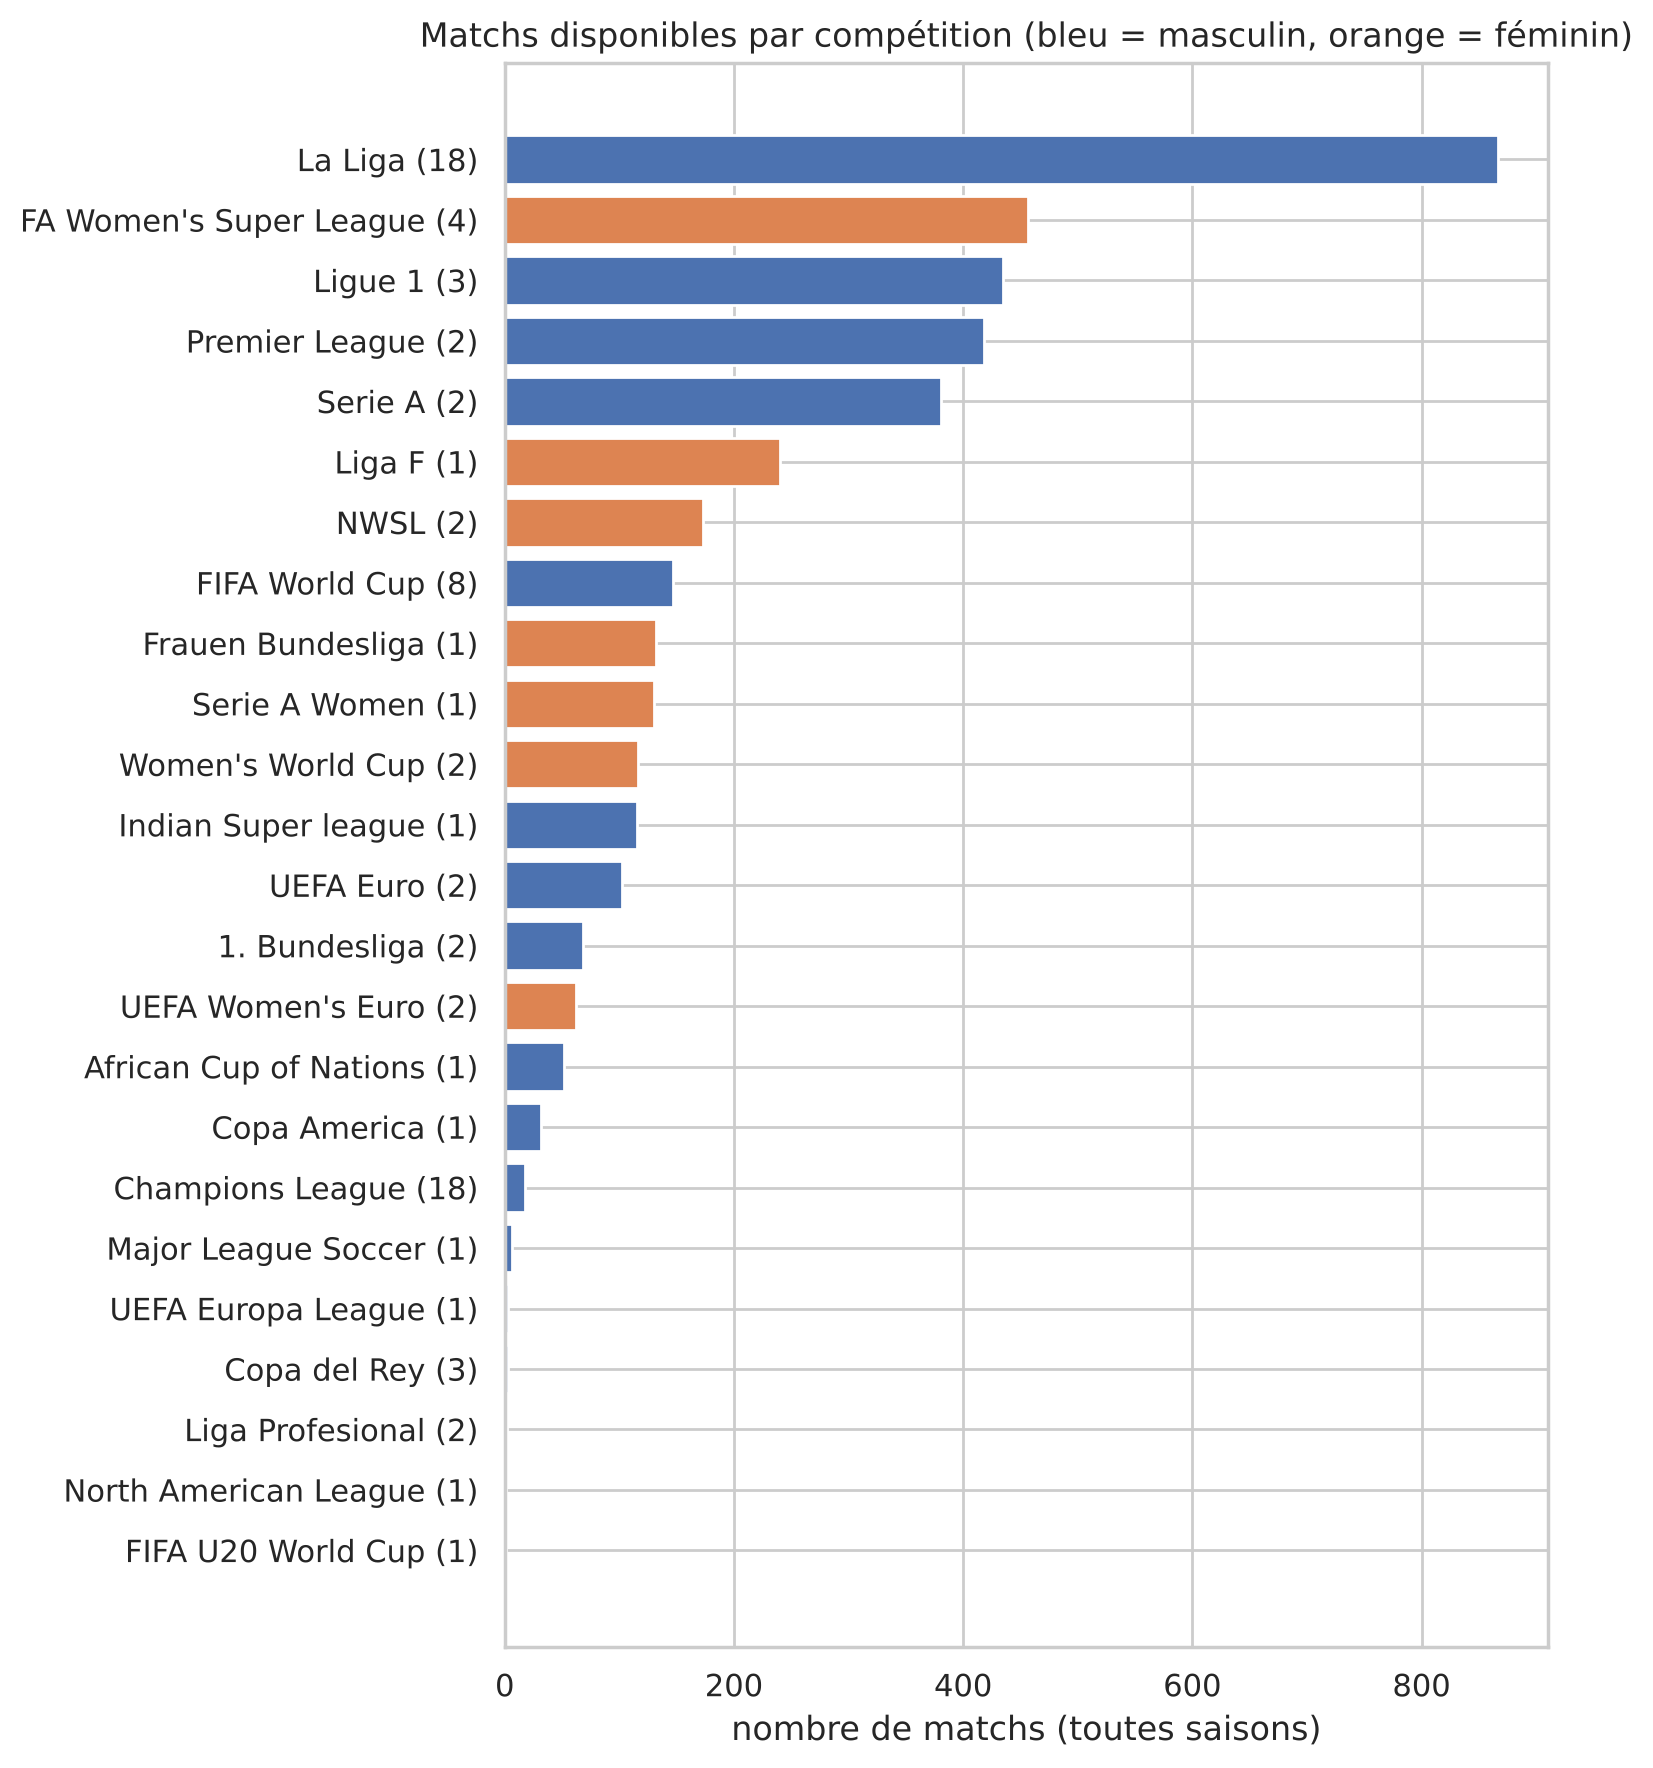

In [3]:
by_comp = (coverage.groupby(["competition", "gender"], as_index=False)
           .agg(n_matches=("n_matches", "sum"), n_seasons=("season", "size"))
           .sort_values("n_matches"))
fig, ax = plt.subplots(figsize=(8, 9))
colors = by_comp.gender.map({"male": "C0", "female": "C1"})
ax.barh(by_comp.competition + " (" + by_comp.n_seasons.astype(str) + ")", by_comp.n_matches, color=colors)
ax.set_xlabel("nombre de matchs (toutes saisons)")
ax.set_title("Matchs disponibles par compétition (bleu = masculin, orange = féminin)")
plt.tight_layout()

**À retenir.** Les 5 grands championnats 2015/16 sont complets (≈ 380 matchs chacun, ~1 800 au
total) : c'est le meilleur jeu d'entraînement pour un xT « classique » dense. Les tournois récents
(Coupe du monde 2022, Euro 2020/2024, etc.) ont des données **360** (positions des joueurs
visibles), utiles si on veut une variante type DxT plus tard. La Liga 2004-2020 ne couvre que les
matchs de Barcelone : à éviter pour l'entraînement (biais d'une seule équipe).

## 2. Table d'actions nettoyée

`bxt.data.build_actions` télécharge chaque match (cache local), aplatit les événements utiles
(passes, conduites/*carries*, dribbles, tirs, pertes de balle…) et applique un nettoyage de base :
séances de tirs au but retirées (période 5), positions sans coordonnées retirées, coordonnées
ramenées dans le terrain 120 × 80. Toutes les équipes attaquent de gauche à droite (x = 120 = but
adverse) : pas besoin de retourner les coordonnées.

In [4]:
PAIRS = [(43, 106), (2, 27)]   # Coupe du monde 2022, Premier League 2015/16
actions = load_actions(PAIRS)
actions = add_cells(actions, NX, NY)
print(actions.shape)
actions.groupby("competition_name").match_id.nunique()

(911403, 37)


competition_name
FIFA World Cup     64
Premier League    380
Name: match_id, dtype: int64

In [5]:
actions.head()

,match_id,event_id,index,period,minute,second,possession,possession_team,team,player,...,success,ambiguous_outcome,set_piece,competition_name,season_name,match_date,ix,iy,cell,end_cell
0,3857286,70734a3c-66ec-495c-8a1d-30a771406518,5,1,0,0,2,Qatar,Qatar,Almoez Ali Zainalabiddin Abdulla,...,True,False,True,FIFA World Cup,2022,2022-11-20,8,6,104,103
1,3857286,b69da27e-4508-4dc9-b32b-b1eacdd4a175,7,1,0,1,2,Qatar,Qatar,Akram Hassan Afif,...,True,False,False,FIFA World Cup,2022,2022-11-20,7,6,103,103
2,3857286,e13f916d-367e-4223-9c22-8c9529ec23b7,8,1,0,2,2,Qatar,Qatar,Akram Hassan Afif,...,True,False,False,FIFA World Cup,2022,2022-11-20,7,6,103,103
3,3857286,aadbb0cb-82e4-496d-aac2-cf8624ab9377,10,1,0,3,2,Qatar,Qatar,Hassan Khalid Al Heidos,...,True,False,False,FIFA World Cup,2022,2022-11-20,7,6,103,103
4,3857286,35397ea8-02ce-4b94-a457-3ef7e7d4d4cf,11,1,0,4,2,Qatar,Qatar,Hassan Khalid Al Heidos,...,False,False,False,FIFA World Cup,2022,2022-11-20,7,6,103,110


In [6]:
counts = (actions.groupby(["competition_name", "type"]).size()
          .unstack(0).fillna(0).astype(int))
counts["par match (PL)"] = (counts["Premier League"] / 380).round(1)
counts.sort_values("Premier League", ascending=False)

competition_name,FIFA World Cup,Premier League,par match (PL)
type,,,
Pass,68515,368619,970.0
Carry,53764,276949,728.8
Ball Recovery,5821,40943,107.7
Clearance,2684,21645,57.0
Dribble,1793,13721,36.1
Miscontrol,1755,10786,28.4
Dispossessed,1431,10520,27.7
Shot,1453,9908,26.1
Foul Won,1693,9112,24.0


## 3. Où se passent les actions ?

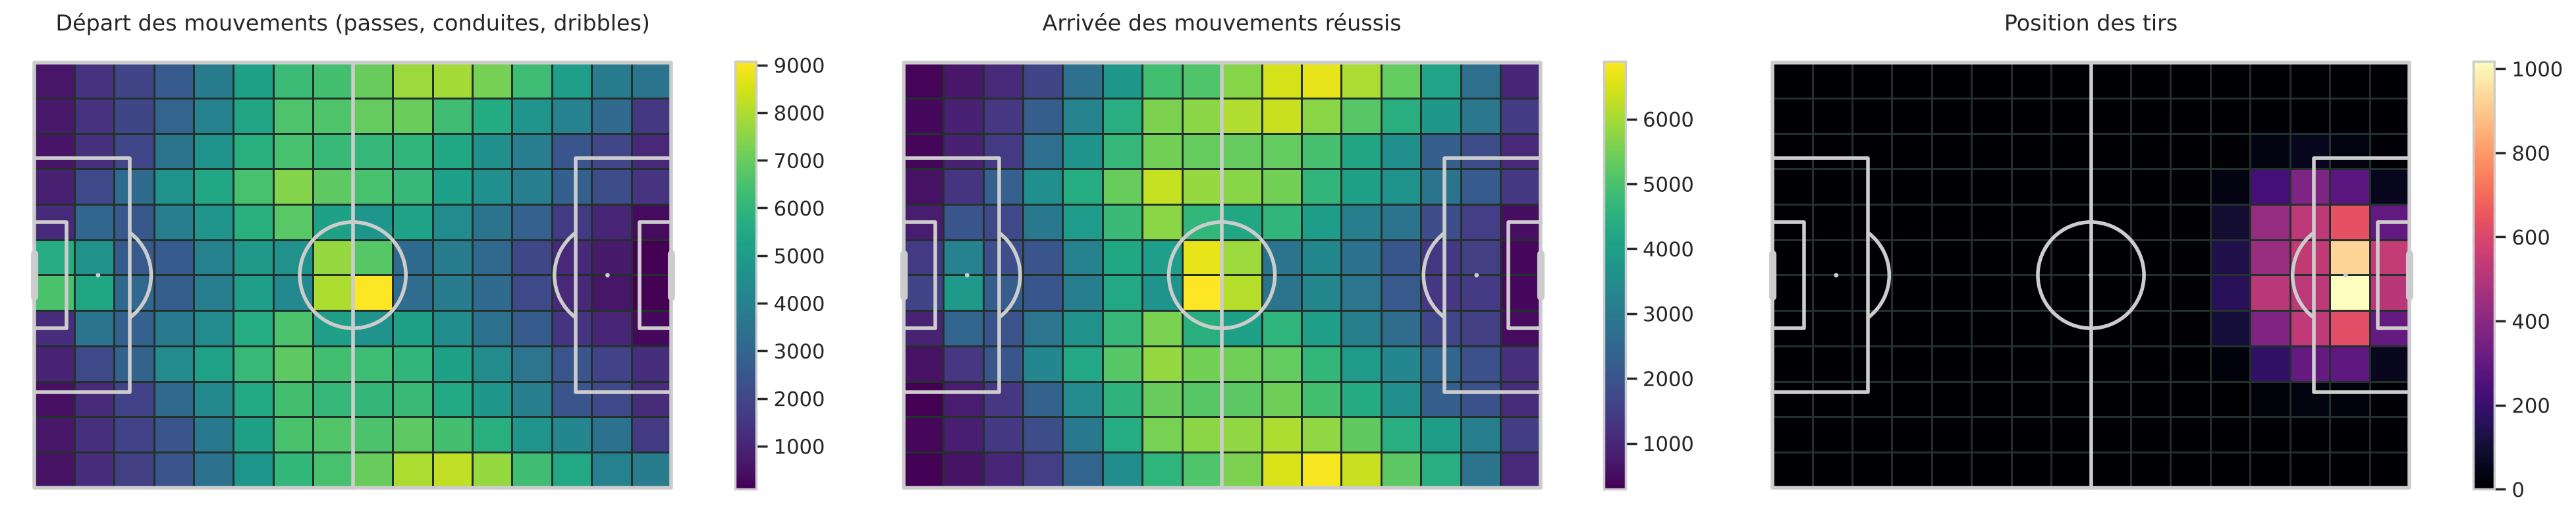

In [7]:
moves = actions[actions.type.isin(["Pass", "Carry", "Dribble"])]
shots = actions[actions.type.eq("Shot")]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
grid_heatmap(count_grid(moves.x, moves.y, NX, NY), ax=axes[0], title="Départ des mouvements (passes, conduites, dribbles)")
ok = moves[moves.success.eq(True) & moves.end_x.notna()]
grid_heatmap(count_grid(ok.end_x, ok.end_y, NX, NY), ax=axes[1], title="Arrivée des mouvements réussis")
grid_heatmap(count_grid(shots.x, shots.y, NX, NY), ax=axes[2], title="Position des tirs", cmap="magma")
plt.tight_layout()

## 4. Réussite des mouvements ($m_z$ et $T$)

Définition de la réussite dans `clean.py` :
* **passe** : pas d'`outcome` (StatsBomb ne met un outcome que si la passe échoue) ;
* **dribble** : outcome `Complete` ;
* **conduite** : réussie sauf si l'événement suivant est un `Dispossessed` / `Miscontrol` du même joueur.

Les passes `Unknown` / `Injury Clearance` sont marquées `ambiguous_outcome` (ce ne sont pas de vraies
pertes de balle).

In [8]:
rate = (moves.groupby(["competition_name", "type"]).success
        .agg(["size", "mean"]).rename(columns={"size": "n", "mean": "taux_reussite"}).round(3))
rate

n  taux_reussite
competition_name type                          
FIFA World Cup   Carry     53764          0.949
                 Dribble    1793          0.523
                 Pass      68515          0.822
Premier League   Carry    276949          0.934
                 Dribble   13721          0.587
                 Pass     368619          0.766

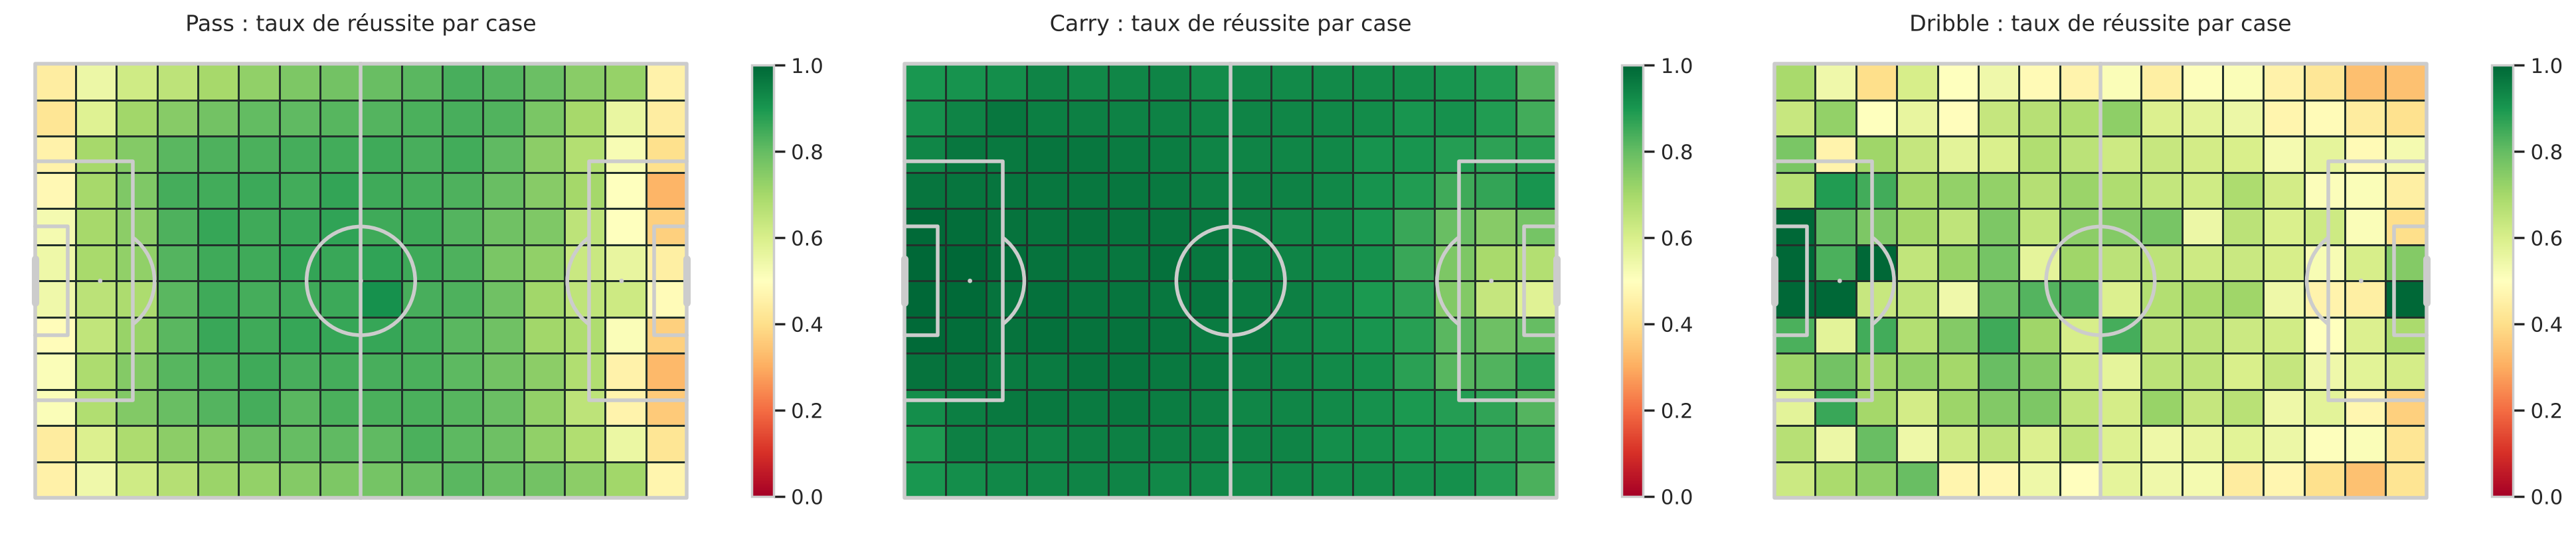

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, t in zip(axes, ["Pass", "Carry", "Dribble"]):
    d = moves[moves.type.eq(t)]
    n = count_grid(d.x, d.y, NX, NY)
    s = count_grid(d.x, d.y, NX, NY, weights=d.success.astype(float))
    with np.errstate(invalid="ignore", divide="ignore"):
        grid_heatmap(np.where(n > 0, s / n, np.nan), ax=ax, title=f"{t} : taux de réussite par case",
                     cmap="RdYlGn", vmin=0, vmax=1)
plt.tight_layout()

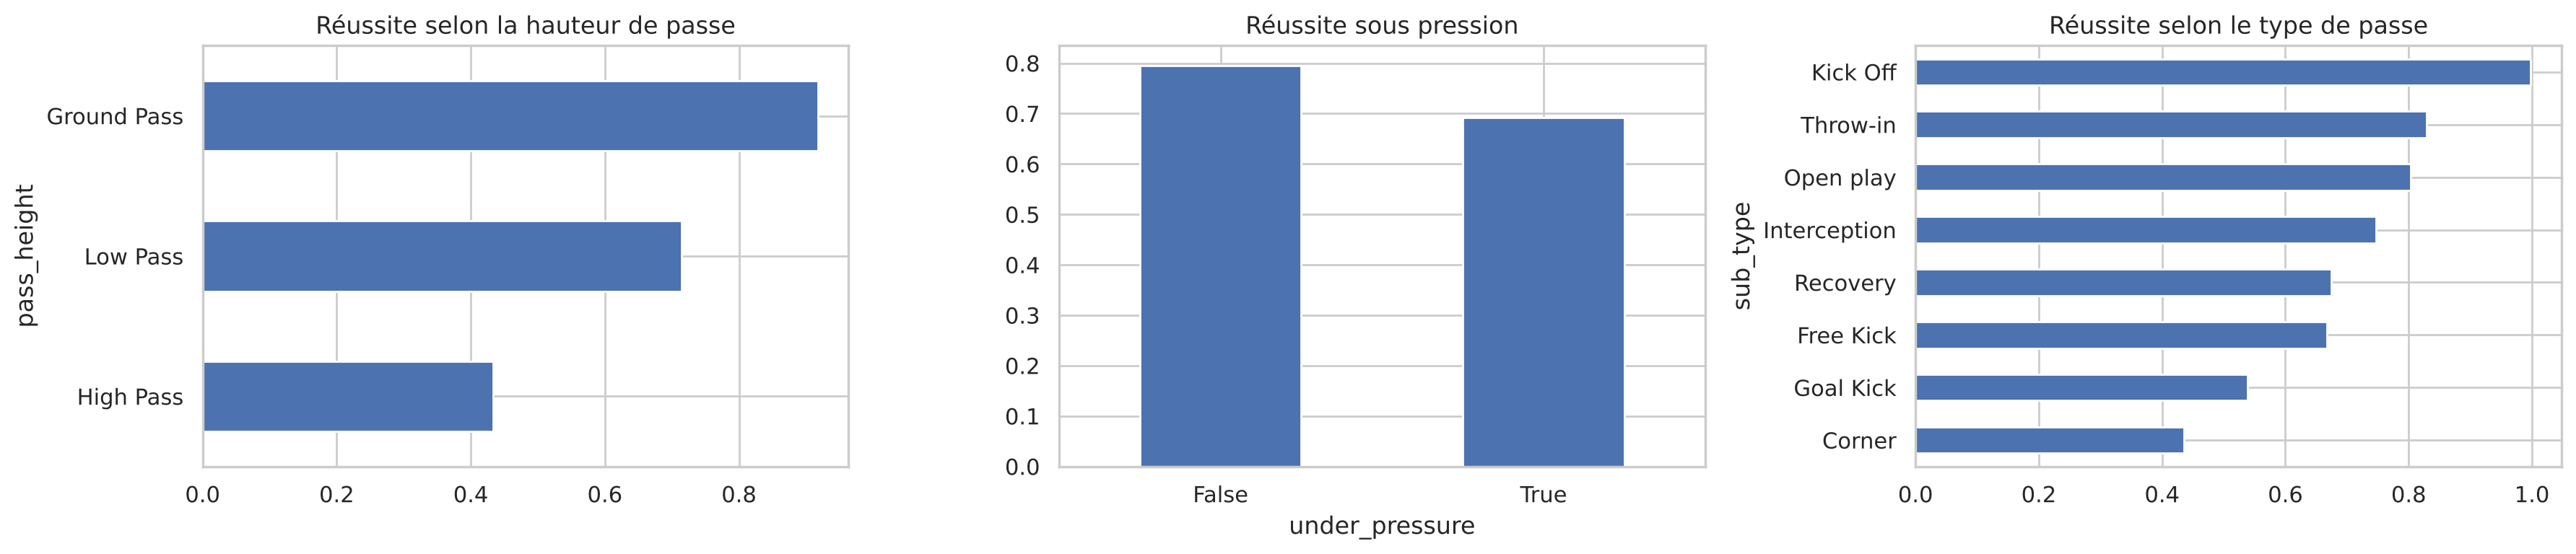

In [10]:
p = moves[moves.type.eq("Pass") & ~moves.ambiguous_outcome]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
p.groupby("pass_height").success.mean().sort_values().plot.barh(ax=axes[0], title="Réussite selon la hauteur de passe")
p.groupby("under_pressure").success.mean().plot.bar(ax=axes[1], title="Réussite sous pression", rot=0)
pt = p.assign(sub_type=p.sub_type.fillna("Open play"))
pt.groupby("sub_type").success.mean().sort_values().plot.barh(ax=axes[2], title="Réussite selon le type de passe")
plt.tight_layout()

Text(0.5, 1.0, 'Progression des passes et conduites réussies')

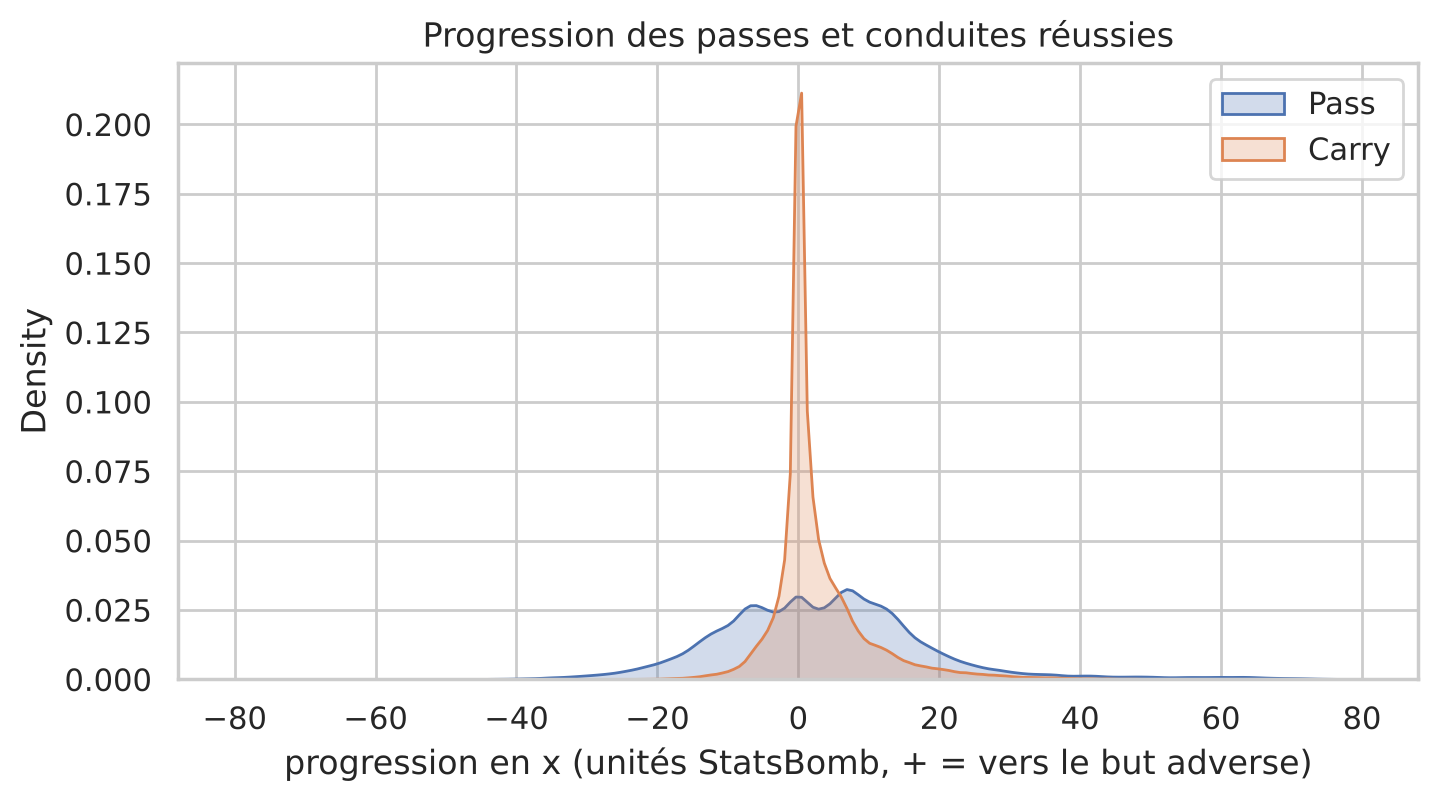

In [11]:
# Distance gagnée vers le but adverse selon le type de mouvement (réussi)
ok = moves[moves.success.eq(True) & moves.end_x.notna()].assign(dx=lambda d: d.end_x - d.x)
fig, ax = plt.subplots(figsize=(8, 4))
for t in ["Pass", "Carry"]:
    sns.kdeplot(ok.loc[ok.type.eq(t), "dx"], ax=ax, label=t, fill=True, bw_adjust=0.8, clip=(-80, 80))
ax.set_xlabel("progression en x (unités StatsBomb, + = vers le but adverse)")
ax.legend(); ax.set_title("Progression des passes et conduites réussies")

## 5. Tirs et buts ($s_z$ et $g_z$)

On compare le taux de but empirique par case au xG de StatsBomb (baseline à battre si on améliore
le xG). Attention : les **buts contre son camp** ne sont pas des tirs, d'où l'écart avec le score
réel. Les penalties sont des tirs à part (type `Penalty`), à traiter séparément dans le modèle.

In [12]:
m_all = pd.concat([load_matches(c, s) for c, s in PAIRS])
real_goals = m_all.groupby("competition_name").apply(lambda m: (m.home_score + m.away_score).sum())
summary = shots.groupby("competition_name").agg(tirs=("is_goal", "size"), buts=("is_goal", "sum"),
                                                 xG_statsbomb=("shot_xg", "sum"),
                                                 penalties=("sub_type", lambda s: (s == "Penalty").sum()))
summary["buts_score_reel"] = real_goals
summary["tirs_par_match"] = (summary.tirs / actions.groupby("competition_name").match_id.nunique()).round(1)
summary.round(1)

,tirs,buts,xG_statsbomb,penalties,buts_score_reel,tirs_par_match
competition_name,,,,,,
FIFA World Cup,1453,169,155.9,23,172,22.7
Premier League,9908,988,971.4,91,1026,26.1


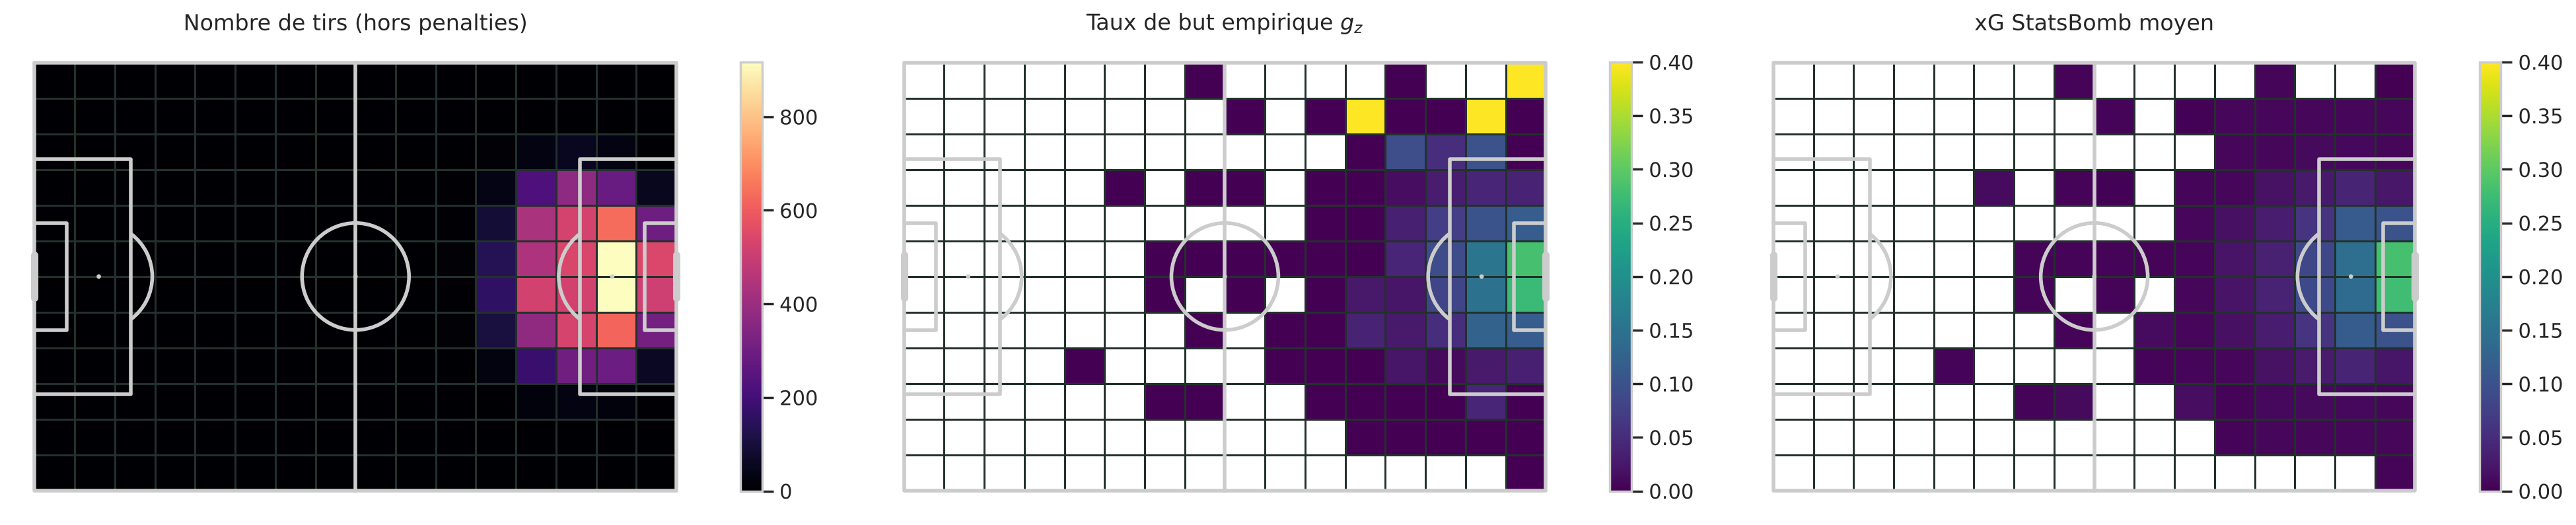

In [13]:
op = shots[shots.sub_type.ne("Penalty")]
n = count_grid(op.x, op.y, NX, NY)
g = count_grid(op.x, op.y, NX, NY, weights=op.is_goal.astype(float))
xg = count_grid(op.x, op.y, NX, NY, weights=op.shot_xg)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
grid_heatmap(n, ax=axes[0], title="Nombre de tirs (hors penalties)", cmap="magma")
with np.errstate(invalid="ignore", divide="ignore"):
    grid_heatmap(np.where(n > 0, g / n, np.nan), ax=axes[1], title="Taux de but empirique $g_z$", cmap="viridis", vmin=0, vmax=0.4)
    grid_heatmap(np.where(n > 0, xg / n, np.nan), ax=axes[2], title="xG StatsBomb moyen", cmap="viridis", vmin=0, vmax=0.4)
plt.tight_layout()

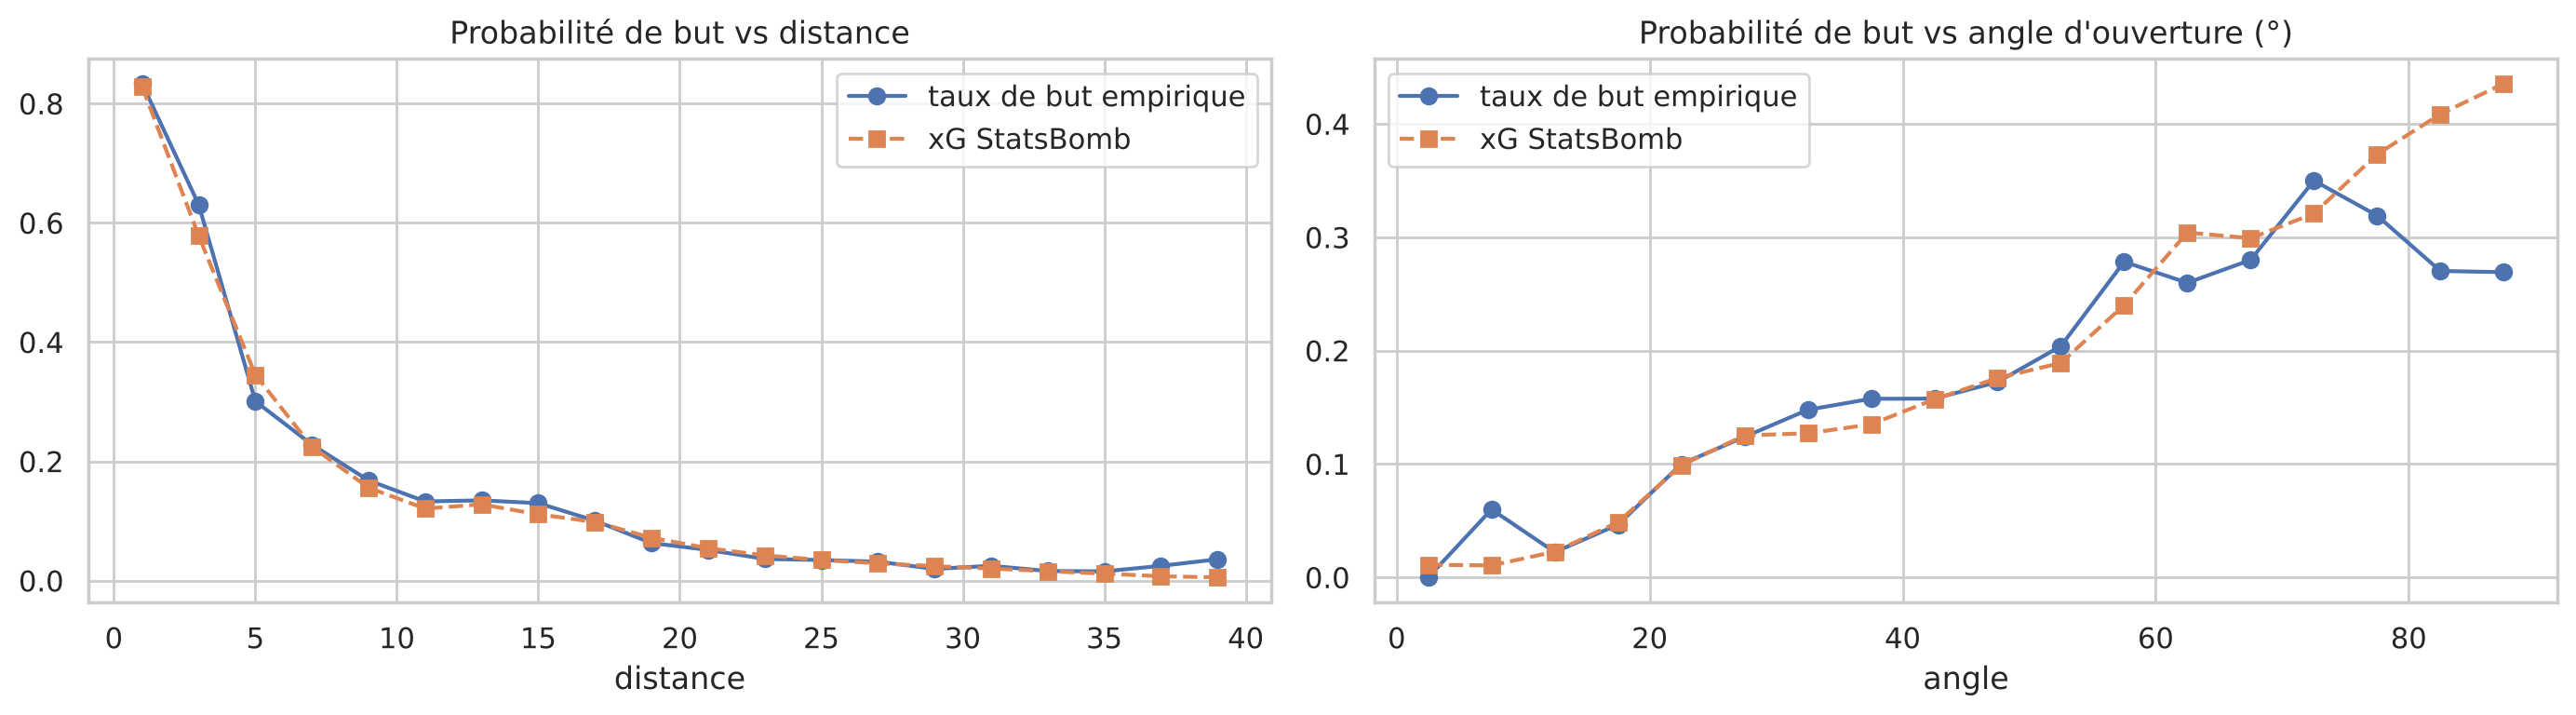

In [14]:
# Distance et angle au but (centre du but en (120, 40), poteaux en y = 36 et 44)
def shot_geometry(df):
    dx, dy = PITCH_X - df.x, PITCH_Y / 2 - df.y
    dist = np.hypot(dx, dy)
    a1 = np.arctan2(44 - df.y, dx); a2 = np.arctan2(36 - df.y, dx)
    return df.assign(distance=dist, angle=np.degrees(np.abs(a1 - a2)))

op = shot_geometry(op)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, bins in [(axes[0], "distance", np.arange(0, 42, 2)), (axes[1], "angle", np.arange(0, 95, 5))]:
    b = pd.cut(op[col], bins)
    t = op.groupby(b, observed=True).agg(taux_but=("is_goal", "mean"), xg=("shot_xg", "mean"), n=("is_goal", "size"))
    centers = [i.mid for i in t.index]
    ax.plot(centers, t.taux_but, "o-", label="taux de but empirique")
    ax.plot(centers, t.xg, "s--", label="xG StatsBomb")
    ax.set_xlabel(col); ax.legend()
axes[0].set_title("Probabilité de but vs distance"); axes[1].set_title("Probabilité de but vs angle d'ouverture (°)")
plt.tight_layout()

## 6. Rareté des données : pourquoi un xT bayésien

L'estimateur classique de xT est un ratio de comptes par case. Avec peu d'observations, ces
ratios sont très bruités, surtout pour $g_z$ (peu de tirs loin du but) et pour la matrice de
transition $T$ (192 × 192 = 36 864 paires de cases).

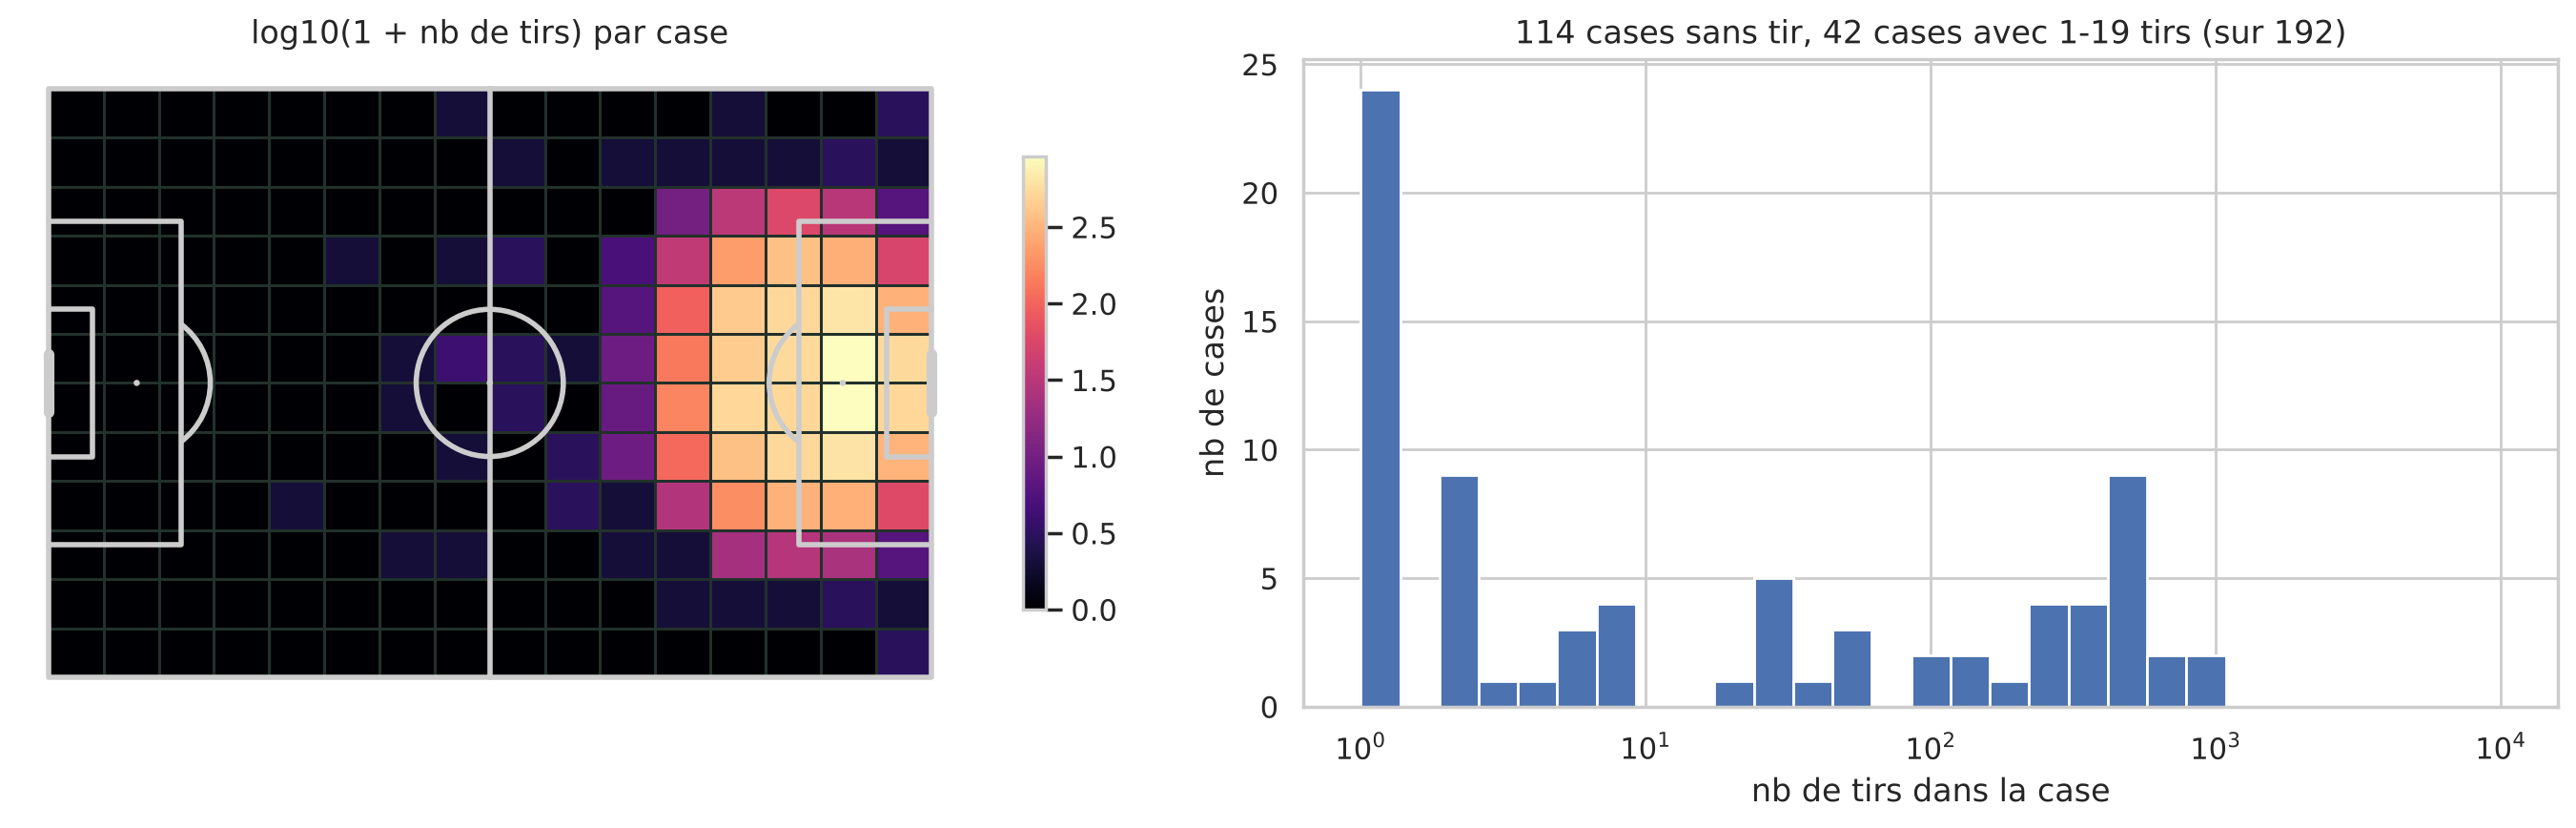

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
grid_heatmap(np.log10(n + 1), ax=axes[0], title="log10(1 + nb de tirs) par case", cmap="magma")
axes[1].hist(n.ravel(), bins=np.logspace(0, 4, 30))
axes[1].set_xscale("log"); axes[1].set_xlabel("nb de tirs dans la case"); axes[1].set_ylabel("nb de cases")
axes[1].set_title(f"{(n == 0).sum()} cases sans tir, {((n > 0) & (n < 20)).sum()} cases avec 1-19 tirs (sur {n.size})")
plt.tight_layout()

In [16]:
ok = moves[moves.success.eq(True) & (moves.end_cell >= 0)]
for comp, d in [("Coupe du monde 2022", ok[ok.competition_name.eq("FIFA World Cup")]),
                ("Premier League 15/16", ok[ok.competition_name.eq("Premier League")]),
                ("Les deux", ok)]:
    T = np.zeros((NX * NY, NX * NY))
    np.add.at(T, (d.cell.values, d.end_cell.values), 1)
    nz = T[T > 0]
    print(f"{comp:22s} {len(d):>8,} mouvements réussis | paires (z, z') observées : {len(nz):>6,} / {T.size:,} "
          f"({len(nz) / T.size:.1%}) | médiane par paire observée : {np.median(nz):.0f} | paires vues < 5 fois : {(nz < 5).mean():.0%}")

Coupe du monde 2022     107,377 mouvements réussis | paires (z, z') observées : 11,479 / 36,864 (31.1%) | médiane par paire observée : 3 | paires vues < 5 fois : 60%
Premier League 15/16    540,922 mouvements réussis | paires (z, z') observées : 18,376 / 36,864 (49.8%) | médiane par paire observée : 6 | paires vues < 5 fois : 46%
Les deux                648,299 mouvements réussis | paires (z, z') observées : 18,997 / 36,864 (51.5%) | médiane par paire observée : 6 | paires vues < 5 fois : 44%


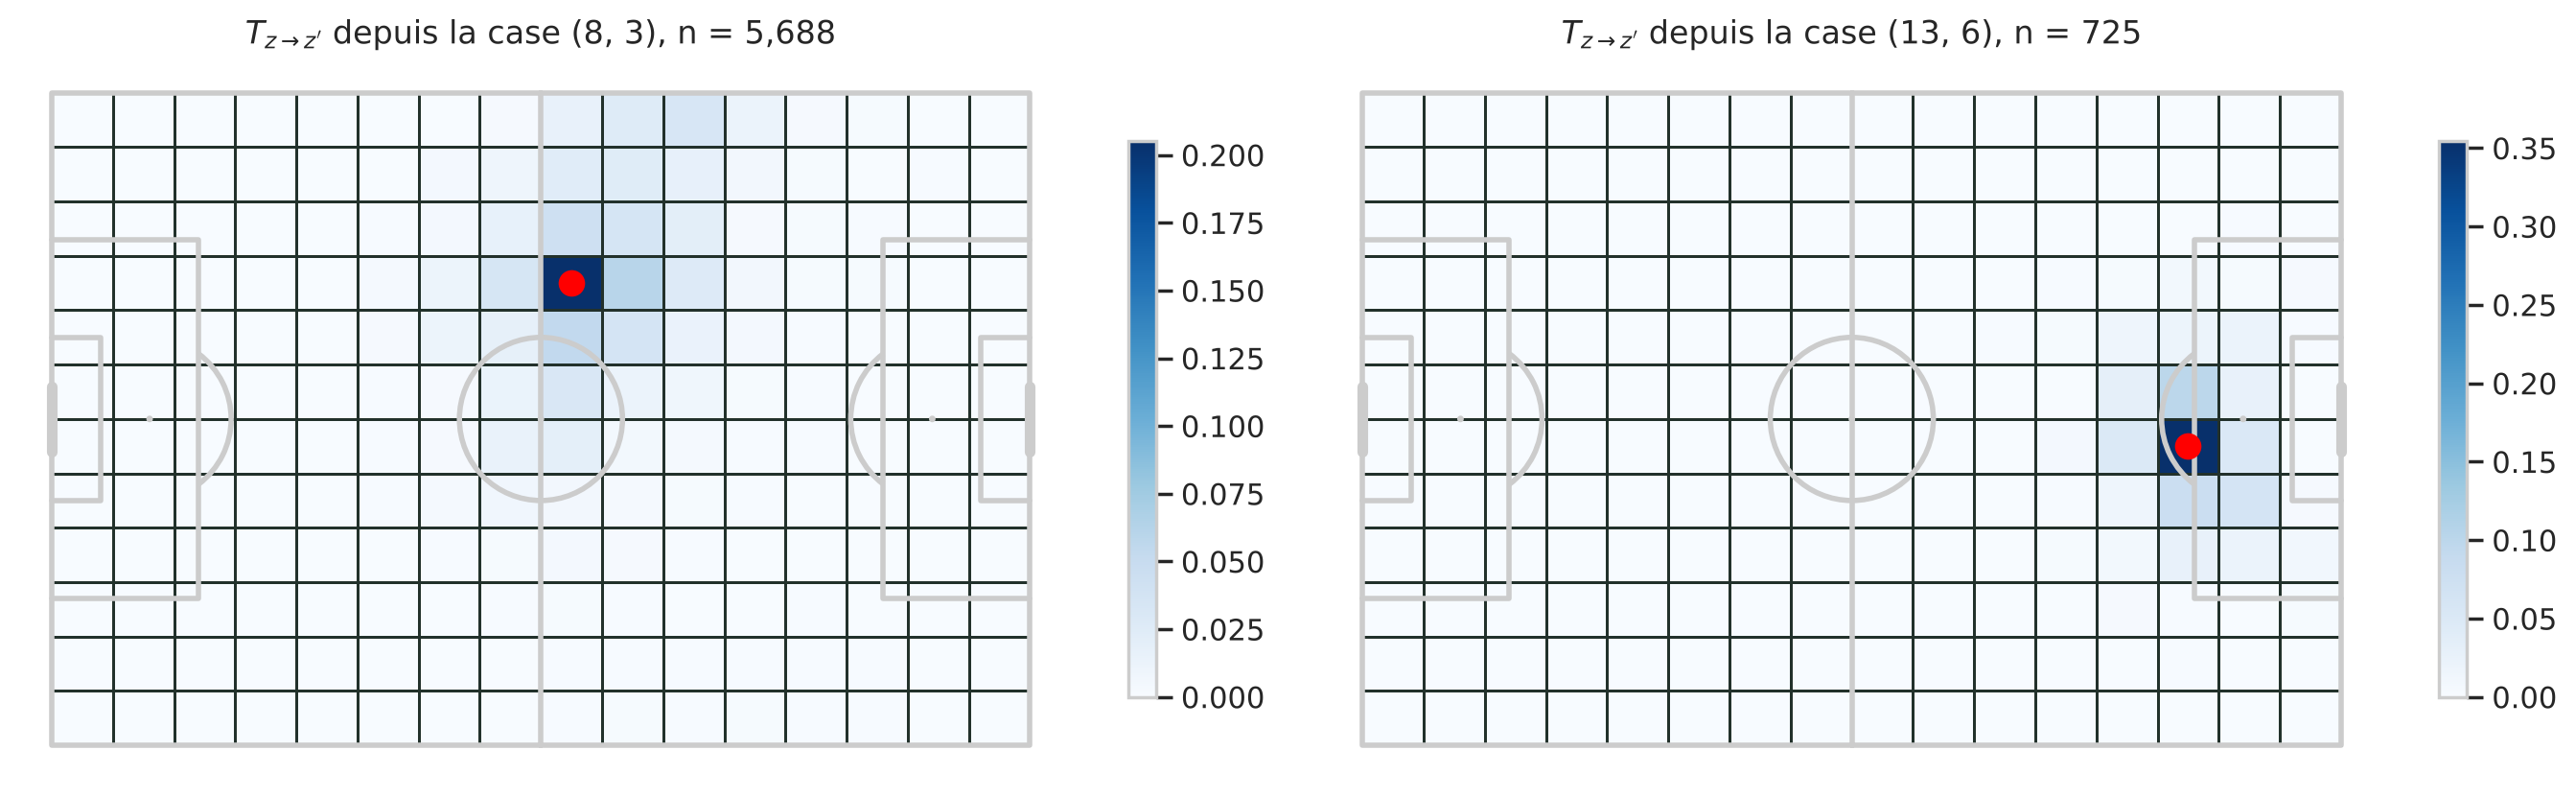

In [17]:
# Visualiser une ligne de T : d'où à où va le ballon depuis une case du milieu droit
T = np.zeros((NX * NY, NX * NY))
np.add.at(T, (ok.cell.values, ok.end_cell.values), 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (ix, iy) in zip(axes, [(8, 3), (13, 6)]):
    z = iy * NX + ix
    row = T[z].reshape(NY, NX)
    grid_heatmap(row / row.sum(), ax=ax, title=f"$T_{{z \\to z'}}$ depuis la case ({ix}, {iy}), n = {int(row.sum()):,}", cmap="Blues")
    ax.scatter((ix + 0.5) * PITCH_X / NX, (iy + 0.5) * PITCH_Y / NY, c="red", s=80, zorder=5)
plt.tight_layout()

## 7. Contrôles qualité

Points vérifiés sur la table nettoyée (à garder en tête pour la modélisation).

In [18]:
checks = {
    "actions": len(actions),
    "mouvements sans position d'arrivée (dribbles, normal)": int(moves.end_x.isna().sum()),
    "passes/conduites sans arrivée": int(moves[moves.type.isin(["Pass", "Carry"])].end_x.isna().sum()),
    "passes au résultat ambigu (Unknown, Injury Clearance)": int(actions.ambiguous_outcome.sum()),
    "tirs sans xG StatsBomb": int(shots.shot_xg.isna().sum()),
    "actions en prolongation (périodes 3-4)": int(actions.period.isin([3, 4]).sum()),
    "conduites de longueur nulle": int((moves.type.eq("Carry") & (moves.x == moves.end_x) & (moves.y == moves.end_y)).sum()),
    "buts contre son camp (écart score réel - buts sur tir)": int(summary.buts_score_reel.sum() - summary.buts.sum()),
}
pd.Series(checks, name="valeur").to_frame()

,valeur
actions,911403
"mouvements sans position d'arrivée (dribbles, normal)",15514
passes/conduites sans arrivée,0
"passes au résultat ambigu (Unknown, Injury Clearance)",2757
tirs sans xG StatsBomb,0
actions en prolongation (périodes 3-4),3265
conduites de longueur nulle,40226
buts contre son camp (écart score réel - buts sur tir),41


## 8. Résumé et suite

* **Données** : pour l'entraînement, les 5 grands championnats 2015/16 (`python scripts/fetch_data.py
  --preset big5_1516`, ~1 800 matchs, ~5 Go de JSON brut) ; garder la Coupe du monde 2022 / Euro
  comme jeu de test hors distribution, et pour les données 360.
* **Mouvements** : ~75-80 % des passes réussissent, ~93 % des conduites, ~55-60 % des dribbles. La
  réussite dépend fortement de la zone, de la hauteur de la passe et de la pression : c'est
  l'argument pour un modèle de transition **par type d'action** plutôt qu'une moyenne.
* **Tirs** : ~10 % de conversion, le xG StatsBomb suit bien le taux empirique. Beaucoup de cases
  ont 0 ou très peu de tirs : $g_z$ empirique est instable, d'où l'intérêt d'un prior (ex.
  Beta-binomial hiérarchique, ou xG paramétrique distance/angle comme prior).
* **Transitions** : seule une petite fraction des 36 864 paires de cases est observée, et la
  plupart rarement : un prior (Dirichlet par case, lissage spatial) devrait beaucoup aider.

Prochaine étape (semaine du 25 nov.) : implémenter le xT classique (itération de valeur) sur
cette table, comme baseline avant la version bayésienne.